In [1]:
from pathlib import Path
import pickle

import numpy as np

DATA_DIR = Path("data/skin_section_2")
FILE_NAMES = [
    "srs_Raman_shift.pickle",
    "arr_calibration_confocal.pickle",
    "skin_srs_small_sampling_hyperspectral_registered_confocal.pickle",
]

for name in FILE_NAMES:
    path = DATA_DIR / name
    size_mb = path.stat().st_size / 1e6
    with open(path, "rb") as f:
        obj = pickle.load(f)
    print(f"The file {name} is {size_mb:.3f} MB and contains an object of type {type(obj).__name__}.")
    if isinstance(obj, dict):
        print(f"The dictionary in {name} has the keys {list(obj.keys())}.")
    else:
        arr = np.asarray(obj)
        print(
            f"The array in {name} has shape {arr.shape} and dtype {arr.dtype}, "
            f"with values from {arr.min():.4g} to {arr.max():.4g}."
        )
        if arr.ndim == 1:
            print(f"The first five values in {name} are {arr[:5]} and the last five are {arr[-5:]}.")

The file srs_Raman_shift.pickle is 0.001 MB and contains an object of type ndarray.
The array in srs_Raman_shift.pickle has shape (125,) and dtype float64, with values from 708.7 to 1750.
The first five values in srs_Raman_shift.pickle are [1750.         1740.76951275 1731.55390659 1722.35314556 1713.16719382] and the last five are [739.36392806 731.69150722 724.03036465 716.3804755  708.74181501].
The file arr_calibration_confocal.pickle is 0.011 MB and contains an object of type ndarray.
The array in arr_calibration_confocal.pickle has shape (1340,) and dtype float64, with values from -126.3 to 1857.
The first five values in arr_calibration_confocal.pickle are [-126.2651677  -124.48400861 -122.70334321 -120.9231713  -119.14349266] and the last five are [1851.96360741 1853.11796547 1854.27207844 1855.42594638 1856.57956939].
The file skin_srs_small_sampling_hyperspectral_registered_confocal.pickle is 45.000 MB and contains an object of type ndarray.
The array in skin_srs_small_samplin

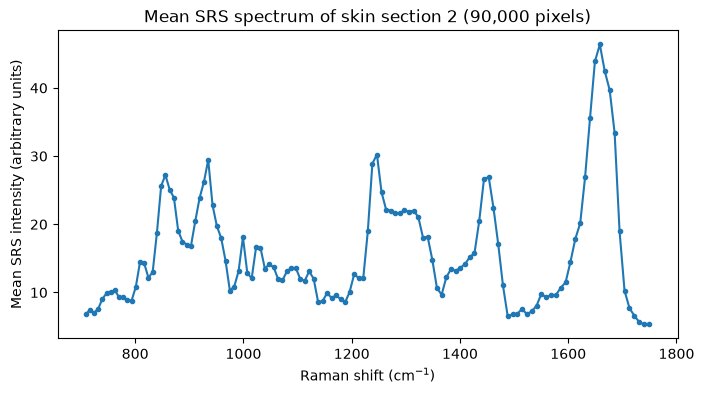

The mean SRS spectrum of skin section 2 has its maximum of 46.4 (arbitrary units) at a Raman shift of 1658.4 cm^-1.


In [2]:
import matplotlib.pyplot as plt

with open(DATA_DIR / "srs_Raman_shift.pickle", "rb") as f:
    raman_shift = pickle.load(f)
with open(DATA_DIR / "skin_srs_small_sampling_hyperspectral_registered_confocal.pickle", "rb") as f:
    cube = pickle.load(f)

order = np.argsort(raman_shift)
shift_sorted = raman_shift[order]
mean_spectrum = cube.reshape(-1, cube.shape[2]).mean(axis=0)[order]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(shift_sorted, mean_spectrum, marker="o", markersize=3)
ax.set_xlabel("Raman shift (cm$^{-1}$)")
ax.set_ylabel("Mean SRS intensity (arbitrary units)")
ax.set_title("Mean SRS spectrum of skin section 2 (90,000 pixels)")
plt.show()

peak_index = np.argmax(mean_spectrum)
print(
    f"The mean SRS spectrum of skin section 2 has its maximum of {mean_spectrum[peak_index]:.1f} "
    f"(arbitrary units) at a Raman shift of {shift_sorted[peak_index]:.1f} cm^-1."
)
